# Seguimiento — Dendrograma y modelo de predicción

**Proyecto:** SGRH — Sistema de Gestión de Recursos Humanos · **Base:** AdventureWorks en PostgreSQL

Este notebook continúa el análisis de [`ead_clusters_rrhh.ipynb`](./ead_clusters_rrhh.ipynb). Allí se agrupó a la plantilla en **5 perfiles** con K-Means. Aquí se hacen las dos tareas nuevas:

1. **Dendrograma.** Un árbol que muestra en qué orden se parecen los empleados, para leer mejor esos 5 perfiles.
2. **Predicción.** Un modelo que anticipa si una persona es **asalariada** o cobra **por horas**, comparando dos algoritmos y quedándose con el de mayor **precisión** (porcentaje de aciertos).

K-Means no dibuja este árbol. El árbol lo construye el agrupamiento jerárquico con el método **Ward**.


## 1. Carga de los mismos empleados

Se usan las mismas reglas que en la actividad anterior: solo empleados activos, se excluyen las pruebas creadas desde la app y el salario es el registro más reciente. Así el dendrograma habla de las mismas 290 personas.


In [1]:
import os, re, warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.1f}".format)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
HOY = pd.Timestamp(date.today())

for carpeta in [Path.cwd(), *Path.cwd().parents]:
    if (carpeta / ".env").exists():
        load_dotenv(carpeta / ".env")
        break
url = re.sub(r"^postgres(ql)?://", "postgresql+psycopg://", os.environ["DATABASE_URL"]).split("?")[0]
engine = create_engine(url, connect_args={"connect_timeout": 15})

consultas = {
    "employee": "SELECT * FROM humanresources.employee",
    "department": "SELECT * FROM humanresources.department",
    "shift": "SELECT * FROM humanresources.shift",
    "historial_depto": "SELECT * FROM humanresources.employeedepartmenthistory",
    "historial_salario": "SELECT * FROM humanresources.employeepayhistory",
    "businessentity": "SELECT businessentityid, modifieddate FROM person.businessentity",
}
with engine.connect() as conn:
    conn.execute(text("SET TRANSACTION READ ONLY"))
    t = {nombre: pd.read_sql(sql, conn) for nombre, sql in consultas.items()}

emp, dh, ph = t["employee"], t["historial_depto"], t["historial_salario"]
fecha_alta = pd.to_datetime(t["businessentity"]["modifieddate"], utc=True)
ids_prueba = t["businessentity"].loc[fecha_alta.dt.year >= 2020, "businessentityid"]

salario = (ph.sort_values("ratechangedate").groupby("businessentityid").tail(1)
           .set_index("businessentityid")["rate"].astype(float).rename("tarifa_hora"))
actual = (dh[dh["enddate"].isna()]
          .merge(t["department"][["departmentid", "name"]], on="departmentid")
          .rename(columns={"name": "departamento"})
          .set_index("businessentityid")[["departamento"]])

def anios(desde):
    return ((HOY - pd.to_datetime(desde)).dt.days / 365.25).astype(int)

df = (emp[emp["currentflag"] & ~emp["businessentityid"].isin(ids_prueba)]
      .set_index("businessentityid").join(salario).join(actual))
df["edad"] = anios(df["birthdate"])
df["antiguedad"] = anios(df["hiredate"])
df["nivel"] = df["organizationlevel"].fillna(0)
df["vacaciones"] = df["vacationhours"]
df["tipo_pago"] = np.where(df["salariedflag"], "Asalariado", "Por horas")
print(f"Empleados analizados: {len(df)}")


Empleados analizados: 290


## 2. Los mismos 5 perfiles de la actividad anterior

Se repite K-Means con las mismas 4 variables (edad, tarifa en logaritmo, nivel y vacaciones), la misma semilla y **k = 5**. K-Means tampoco recorre las variables en orden: las usa todas a la vez y solo devuelve un número de grupo por empleado.

Los **nombres** sí los ponemos nosotros, después, leyendo los promedios. Ahí sí hay un orden, y es solo de lectura: el salario separa dirección y profesionales; entre los tres grupos de operarios, que ganan casi lo mismo, la edad y las vacaciones alcanzan para distinguirlos. Otra persona podría bautizar los mismos números con otras palabras. El reparto de los 290 empleados no cambiaría.

Esas etiquetas sirven para dos cosas: pintar el dendrograma y comprobar si el árbol, al cortarlo en 5, recupera los mismos perfiles.


In [2]:
VARIABLES = ["edad", "tarifa_hora", "nivel", "vacaciones"]
datos = df[VARIABLES].copy()
datos["tarifa_hora"] = np.log(datos["tarifa_hora"])
X = StandardScaler().fit_transform(datos)

K = 5
df["grupo"] = KMeans(n_clusters=K, n_init=50, random_state=42).fit_predict(X)

promedios = df.groupby("grupo").agg(
    edad=("edad", "mean"),
    salario_hora=("tarifa_hora", "mean"),
    nivel=("nivel", "mean"),
    vacaciones=("vacaciones", "mean"),
)
nombres = {}
pendientes = promedios.copy()

g = pendientes["salario_hora"].idxmax()
nombres[g] = "Dirección y gerencia"
pendientes = pendientes.drop(g)

g = pendientes["salario_hora"].idxmax()
nombres[g] = "Profesionales y administrativos"
pendientes = pendientes.drop(g)

g = pendientes["edad"].idxmax()
nombres[g] = "Operarios veteranos"
pendientes = pendientes.drop(g)

g = pendientes["vacaciones"].idxmax()
nombres[g] = "Operarios jóvenes con muchas vacaciones"
g = pendientes["vacaciones"].idxmin()
nombres[g] = "Operarios con pocas vacaciones"

df["perfil"] = df["grupo"].map(nombres)
ORDEN = [
    "Operarios con pocas vacaciones",
    "Operarios jóvenes con muchas vacaciones",
    "Operarios veteranos",
    "Profesionales y administrativos",
    "Dirección y gerencia",
]
df["perfil"].value_counts().reindex(ORDEN).rename("empleados").to_frame()


,empleados
perfil,
Operarios con pocas vacaciones,93
Operarios jóvenes con muchas vacaciones,57
Operarios veteranos,42
Profesionales y administrativos,84
Dirección y gerencia,14


## 3. Dendrograma

El agrupamiento jerárquico empieza con cada empleado solo y une, paso a paso, a los más parecidos. **Ward** elige la unión que menos aumenta la dispersión interna del grupo. El dibujo de todas esas uniones es el dendrograma.

Ward **no compara una propiedad y después otra**. Cada empleado es un punto en las cuatro variables ya estandarizadas, y la distancia entre dos personas es un solo número: la suma de las diferencias al cuadrado en edad, tarifa, nivel y vacaciones. Una persona puede parecerse en edad y alejarse en sueldo; Ward ve el total, no un turno por variable. El orden «primero salario, luego edad, luego vacaciones» de la sección anterior no es un paso de este método.

- El **eje vertical** es esa distancia conjunta: una unión baja junta personas casi iguales en las cuatro variables; una unión alta mezcla grupos distintos.
- El **corte** es una línea horizontal. Cada rama que atraviesa es un grupo. Más arriba, menos grupos y más mezclados.
- En el **eje horizontal** no hay una marca por empleado. El dibujo muestra solo las últimas 20 uniones, porque 290 hojas no se leen. Cada marca es un montón ya armado más abajo; el número entre paréntesis es cuántas personas van dentro. Esos paréntesis suman 290.

Abajo, el gráfico de barras justifica lo de «las cuatro a la vez»: toma los dos perfiles más lejanos y parte su distancia en el aporte de cada variable. Las cuatro entran en la misma suma. Si una pesa más, es porque en los datos esos grupos se diferencian más ahí, no porque Ward la mire primero.

La figura del árbol trae la línea del corte que deja exactamente 5 grupos, el mismo k de la actividad anterior.


### Las cuatro variables entran en la misma distancia


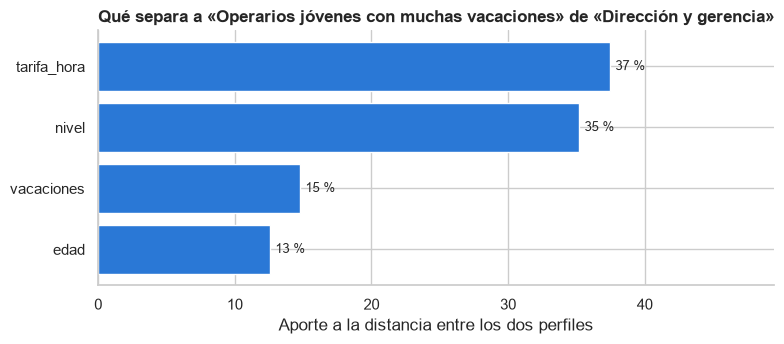

La barra más larga pesa más en esta pareja. Ward igual las suma todas antes de decidir la unión.


In [3]:
centroides = (pd.DataFrame(X, columns=VARIABLES, index=df.index)
              .groupby(df["perfil"]).mean().loc[ORDEN])

mejor = None
for i, perfil_a in enumerate(ORDEN):
    for perfil_b in ORDEN[i + 1:]:
        diferencia = (centroides.loc[perfil_a] - centroides.loc[perfil_b]) ** 2
        if mejor is None or diferencia.sum() > mejor[0]:
            mejor = (diferencia.sum(), perfil_a, perfil_b, diferencia)

distancia, perfil_a, perfil_b, diferencia = mejor
aporte = (diferencia / distancia * 100).sort_values(ascending=True)

plt.figure(figsize=(8, 3.6))
plt.barh(aporte.index, aporte.values, color=PALETA[0])
for nombre, valor in aporte.items():
    plt.text(valor + 0.4, nombre, f"{valor:.0f} %", va="center", fontsize=9)
plt.xlim(0, aporte.max() + 12)
plt.xlabel("Aporte a la distancia entre los dos perfiles")
plt.title(f"Qué separa a «{perfil_a}» de «{perfil_b}»")
plt.tight_layout()
plt.show()
print("La barra más larga pesa más en esta pareja. Ward igual las suma todas antes de decidir la unión.")


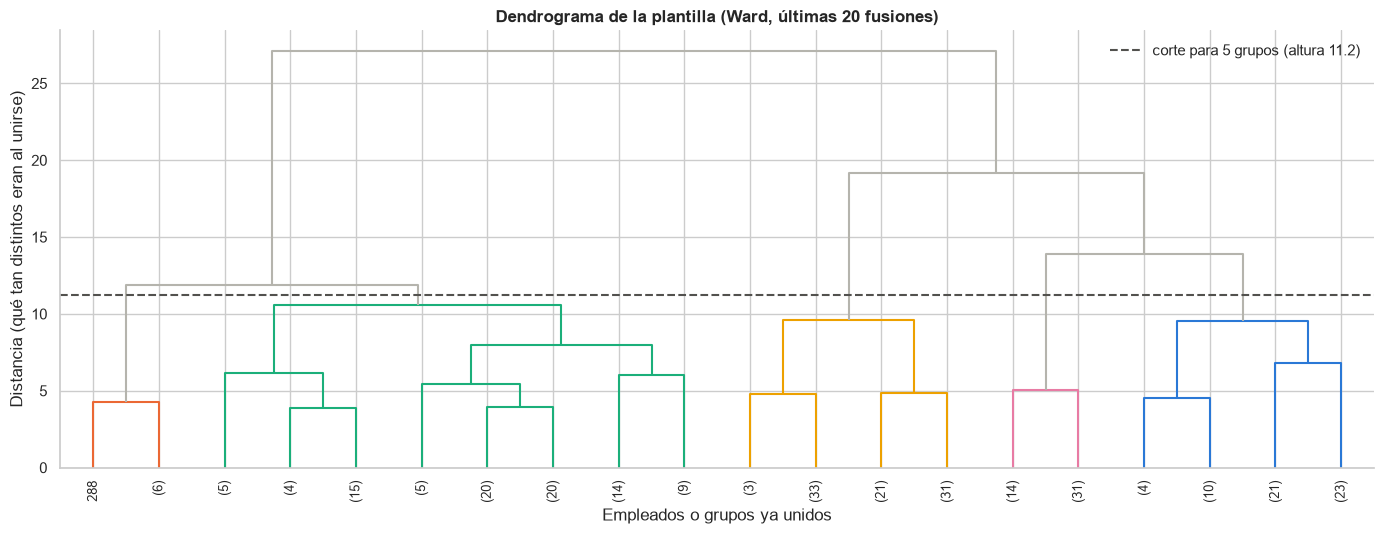

In [4]:
Z = linkage(X, method="ward")
# Altura intermedia entre la fusión que deja K grupos y la siguiente.
corte = (Z[-(K - 1), 2] + Z[-K, 2]) / 2

plt.figure(figsize=(14, 5.5))
dendrogram(
    Z, truncate_mode="lastp", p=20, color_threshold=corte,
    above_threshold_color="#b5b4ad", leaf_rotation=90, leaf_font_size=9,
)
plt.axhline(corte, color="#52514e", ls="--", lw=1.5, label=f"corte para 5 grupos (altura {corte:.1f})")
plt.title("Dendrograma de la plantilla (Ward, últimas 20 fusiones)")
plt.xlabel("Empleados o grupos ya unidos")
plt.ylabel("Distancia (qué tan distintos eran al unirse)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


### Cómo se lee este corte

Por debajo de la línea punteada cada color es un grupo que Ward ya considera unido. A esa altura el árbol queda en **5 ramas**.

Lo que se ve en las alturas, antes de ponerle nombre a cada rama:

- Las uniones **bajas** están entre operarios. Ganan casi lo mismo; solo se separan por edad y vacaciones, así que el árbol los junta pronto.
- Hay una rama que se desprende **muy arriba**: para mezclarla con las demás hay que aceptar una distancia grande. Esa rama es la más distinta de la plantilla.
- Entre esas dos zonas queda un grupo intermedio, separado de producción pero no tan lejos como la rama alta.

La tabla de la sección siguiente dice quién cayó en cada rama. El color del dibujo no trae el nombre del perfil: el nombre se lee en el cruce con K-Means.


### ¿El árbol recupera los perfiles de K-Means?

Se corta el árbol en 5 y se cruza con la etiqueta de K-Means. Si cada fila se concentra en una sola columna, los dos métodos vieron la misma estructura.


In [5]:
df["grupo_ward"] = fcluster(Z, t=K, criterion="maxclust")
cruce = pd.crosstab(df["perfil"], df["grupo_ward"]).reindex(ORDEN)
cruce.columns = [f"rama {c}" for c in cruce.columns]
cruce


,rama 1,rama 2,rama 3,rama 4,rama 5
perfil,,,,,
Operarios con pocas vacaciones,0,1,85,1,6
Operarios jóvenes con muchas vacaciones,0,0,0,44,13
Operarios veteranos,0,0,3,0,39
Profesionales y administrativos,0,84,0,0,0
Dirección y gerencia,7,7,0,0,0


Ward **no copia** los 5 nombres de K-Means. El cruce se lee así:

- **Profesionales:** las 84 personas caen en la rama 2. Es el grupo más estable.
- **Dirección:** se parte en dos. 7 quedan solas en la rama 1 (la que se desprende arriba) y las otras 7 se van con los profesionales a la rama 2. El árbol separa a la alta dirección de los mandos que K-Means había dejado en el mismo perfil.
- **Operarios con pocas vacaciones:** 85 de 93 van a la rama 3.
- **Operarios jóvenes y veteranos:** la mayoría tiene su rama (4 y 5), pero una parte se mezcla entre sí. Están cerca: el sueldo es parecido y solo cambian la edad y las vacaciones, así que un corte fijo en 5 no los separa tan limpio como K-Means.

Eso es el análisis de más que pedía el dendrograma. K-Means entrega 5 cajas. El árbol muestra cuáles de esas cajas están pegadas y cuál (la alta dirección) está lejos.


## 4. Qué se va a predecir

El dendrograma agrupa; no adivina una respuesta. Ahora sí hay una respuesta conocida en la base: **`tipo_pago`**, asalariado o por horas.

En la actividad anterior esa columna **no se usó** para formar los clusters, y aun así dirección salió 100 % asalariada y los operarios 0 %. La pregunta del modelo es si, **con datos del cargo y de la persona, se puede anticipar el tipo de pago**.

**Características (lo que el modelo ve):** edad, antigüedad, nivel jerárquico, horas de vacaciones y departamento.

**Se deja fuera la tarifa por hora.** Quien ya gana como gerente es, casi siempre, asalariado. Incluir el sueldo haría el ejercicio demasiado fácil y no mostraría si el cargo basta para predecir.

**Precisión** en este notebook es el porcentaje de empleados bien clasificados sobre personas que el modelo no usó para aprender.


In [6]:
# Departamento con menos de 8 personas se agrupa: si no, el modelo memoriza áreas diminutas.
conteo_depto = df["departamento"].value_counts()
df["area"] = df["departamento"].where(df["departamento"].map(conteo_depto) >= 8, "Otras áreas")

columnas_num = ["edad", "antiguedad", "nivel", "vacaciones"]
X_modelo = pd.get_dummies(df[columnas_num + ["area"]], columns=["area"], drop_first=True)
y = df["tipo_pago"]

print("Clases en toda la plantilla:")
print(y.value_counts().to_string())
piso = (y == "Por horas").mean()
print(f"\nAdivinar siempre «Por horas» acertaría el {piso:.1%}.")
print("Esa cifra es el piso: un modelo útil tiene que superarla.")


Clases en toda la plantilla:
tipo_pago
Por horas     238
Asalariado     52

Adivinar siempre «Por horas» acertaría el 82.1%.
Esa cifra es el piso: un modelo útil tiene que superarla.


## 5. Dos algoritmos, la misma prueba

Los dos ven las mismas filas de entrenamiento y se califican con las mismas filas de prueba (25 % de la plantilla, repartidas al azar pero respetando la proporción de asalariados).

| Algoritmo | Qué tipo de regla aprende |
|---|---|
| **Regresión logística** | Un puntaje: suma nivel, área, edad y vacaciones con un peso cada uno, y con eso decide asalariado o por horas. Antes de sumar, deja cada número en la misma escala para que la edad (cerca de 45) no pese más que el nivel (0 a 4) solo por ser más grande. |
| **Árbol de decisión** | Preguntas seguidas («¿el nivel es menor que 3?», «¿el área es Producción?»). La profundidad se limita a 4 para que no memorice cada empleado. |

El mejor es el de **mayor precisión en el conjunto de prueba**.


In [7]:
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X_modelo, y, test_size=0.25, random_state=42, stratify=y,
)

modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, random_state=42),
}

filas = []
predicciones = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_ent, y_ent)
    pred = modelo.predict(X_prueba)
    predicciones[nombre] = pred
    filas.append({
        "algoritmo": nombre,
        "precisión en prueba": accuracy_score(y_prueba, pred),
        "aciertos": int((pred == y_prueba).sum()),
        "empleados de prueba": len(y_prueba),
    })

comparacion = pd.DataFrame(filas).sort_values("precisión en prueba", ascending=False)
vista = comparacion.copy()
vista["precisión en prueba"] = vista["precisión en prueba"].map(lambda v: f"{v:.1%}")
vista


,algoritmo,precisión en prueba,aciertos,empleados de prueba
0,Regresión logística,90.4%,66,73
1,Árbol de decisión,89.0%,65,73


In [8]:
mejor = comparacion.iloc[0]
print(f"Mejor modelo: {mejor['algoritmo']}")
print(f"Precisión: {mejor['precisión en prueba']:.1%} ({int(mejor['aciertos'])} de {int(mejor['empleados de prueba'])})")


Mejor modelo: Regresión logística
Precisión: 90.4% (66 de 73)


### Dónde se equivoca el ganador

La precisión resume todo en un número. La matriz dice si el error está en los asalariados (el grupo chico, cerca del 18 %) o en la mayoría que cobra por horas. Un modelo que siempre dijera «por horas» acertaría mucho y fallaría todos los asalariados.


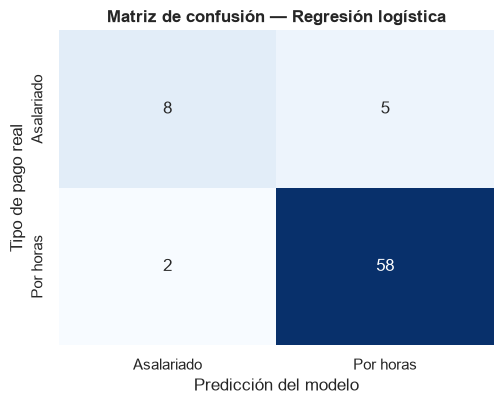

              precision    recall  f1-score   support

  Asalariado      0.800     0.615     0.696        13
   Por horas      0.921     0.967     0.943        60

    accuracy                          0.904        73
   macro avg      0.860     0.791     0.819        73
weighted avg      0.899     0.904     0.899        73



In [9]:
ganador = mejor["algoritmo"]
etiquetas = ["Asalariado", "Por horas"]
matriz = confusion_matrix(y_prueba, predicciones[ganador], labels=etiquetas)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=ax)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Tipo de pago real")
ax.set_title(f"Matriz de confusión — {ganador}")
plt.tight_layout()
plt.show()

print(classification_report(y_prueba, predicciones[ganador], labels=etiquetas, digits=3))


## 6. Conclusiones

1. **El corte en 5 grupos sigue siendo razonable, y el árbol lo matiza.** Profesionales quedan juntos. La alta dirección se separa en su propia rama. Los tres perfiles de operarios están cerca: Ward mezcla a algunos jóvenes con veteranos porque el sueldo no los distingue.
2. **Dirección no es un solo bloque.** K-Means la había dejado como un perfil de 14 personas. El dendrograma parte ese perfil: la mitad se une a profesionales y la mitad queda aislada a gran distancia.
3. **El tipo de pago se puede anticipar sin mirar el sueldo.** Adivinar siempre «por horas» acertaría el 82.1 %. Los dos algoritmos superan ese piso en los 73 empleados de prueba.
4. **El mejor modelo es la regresión logística, con 90.4 % de precisión (66 de 73).** El árbol de decisión queda en 89.0 % (65 de 73): la diferencia es una persona. En los asalariados, que son pocos, la logística acierta cerca de 6 de cada 10; el resto del acierto viene de la mayoría que cobra por horas.
